# 08 · Caracterización de los conglomerados y exportación para Tableau

**Objetivo específico 3 del protocolo:** *caracterizar cada conglomerado según los patrones predominantes y representarlos visualmente mediante un mapa coroplético*.

**Modelo:** K-means, $k = 5$ (notebook 07). Este notebook **valida** si los perfiles de $k = 5$ se sostienen en las **tasas reales** y no solo en las variables transformadas del modelo.

| Sección | Pregunta |
|---|---|
| 2 | ¿Qué tamaño y peso tiene cada grupo (municipios, población, denuncias)? |
| 3 | ¿Cuáles son sus **tasas reales** por 100 mil habitantes y cómo se comparan con la nacional? |
| 4 | ¿Qué **mezcla** de delitos caracteriza a cada grupo? |
| 5 | ¿Qué tan **grandes** son las diferencias entre grupos en cada delito? |
| 6 | ¿Cómo **evolucionaron** entre 2022 y 2025? |
| 7 | ¿Qué municipios representan mejor a cada grupo y cuáles son de frontera? |
| 8 | **Nombres** de los grupos, con validación automática |
| 9 | ¿Dónde están? Composición territorial, **mapa** y **autocorrelación espacial** |
| 10 | Exportación de datasets para **Tableau** |

> **Nota:** los grupos se formaron con 10 variables (R4b), pero se caracterizan con los **12 delitos originales**, en tasas observadas, para que la descripción sea directa e interpretable.

## 0. Configuración

In [1]:
import sys
import json
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Patch
from scipy import stats
from IPython.display import display

from src.utilidades import (RUTA_PROCESSED, RAIZ as RAIZ_PROY, ANIOS_ESTUDIO, DELITOS, CODIGOS_DELITO,
                            CODIGO_A_CORTO, FAMILIA_DELITO, COLOR, COLOR_CLUSTER, CMAP_DIVERGENTE,
                            configurar_estilo, subtitulo, fuente, guardar_figura)

configurar_estilo()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CARPETA_FIG = "08_caracterizacion"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
RUTA_REPORTES = RAIZ_PROY / "outputs" / "reports"
RUTA_TABLEAU = RAIZ_PROY / "outputs" / "tableau"
RUTA_TABLEAU.mkdir(parents=True, exist_ok=True)
GRUPOS = [1, 2, 3, 4, 5]
FAMILIA_COD = {DELITOS[d]: f for d, f in FAMILIA_DELITO.items()}

## 1. Carga de datos

In [2]:
resultado = pd.read_csv(RUTA_PROCESSED / "resultado_agrupamiento.csv", encoding="utf-8-sig").set_index("Codigo_Municipio")
base = pd.read_csv(RUTA_PROCESSED / "base_municipal_2022_2025.csv", encoding="utf-8-sig").set_index("Codigo_Municipio")
suav = pd.read_csv(RUTA_PROCESSED / "tasas_suavizadas_2022_2025.csv", encoding="utf-8-sig").set_index("Codigo_Municipio")
poblacion = pd.read_csv(RUTA_PROCESSED / "poblacion_municipal_2015_2035.csv", encoding="utf-8-sig")
poblacion = poblacion[poblacion["Anio"].isin(ANIOS_ESTUDIO)]
denuncias = pd.read_csv(RUTA_PROCESSED / "denuncias_municipio_anio_delito.csv", encoding="utf-8-sig")
with open(RUTA_REPORTES / "07_modelo_final.json", encoding="utf-8") as f:
    modelo = json.load(f)

# Denuncias anuales con código INE (el archivo del MP usa sus propios nombres)
llave = base.reset_index()[["Codigo_Municipio", "Departamento", "Municipio_MP"]]
denuncias = denuncias.merge(llave, left_on=["Departamento", "Municipio"],
                            right_on=["Departamento", "Municipio_MP"], validate="many_to_one")

exposicion = poblacion.groupby("Codigo_Municipio")["Poblacion"].sum()       # persona-años 2022-2025
conteos = base[[f"n_{c}" for c in CODIGOS_DELITO]].set_axis(CODIGOS_DELITO, axis=1)
tasas = base[[f"tasa_{c}" for c in CODIGOS_DELITO]].set_axis(CODIGOS_DELITO, axis=1)
grupo = resultado["grupo"]

assert grupo.index.equals(base.index) and len(grupo) == 340
print(f"Modelo: {modelo['algoritmo']}, k = {modelo['k']} · tamaños {modelo['tamanos']}")

Modelo: K-means, k = 5 · tamaños [71, 77, 42, 95, 55]


## 2. Tamaño y peso de cada grupo

,municipios,población promedio,denuncias 2022-2025,% municipios,% población,% denuncias,tasa total (x100 mil/año),población mediana municipal
grupo,,,,,,,,
1,71,"3,459,336.50",12550,20.88,19.52,2.88,90.70,"42,310.50"
2,77,"3,011,299.50",27150,22.65,16.99,6.24,225.40,"24,473.75"
3,42,"1,997,776.25",16321,12.35,11.27,3.75,204.24,"33,546.62"
4,95,"3,607,626.25",65079,27.94,20.36,14.96,450.98,"27,480.25"
5,55,"5,644,776.25",313943,16.18,31.85,72.16,"1,390.41","57,686.50"


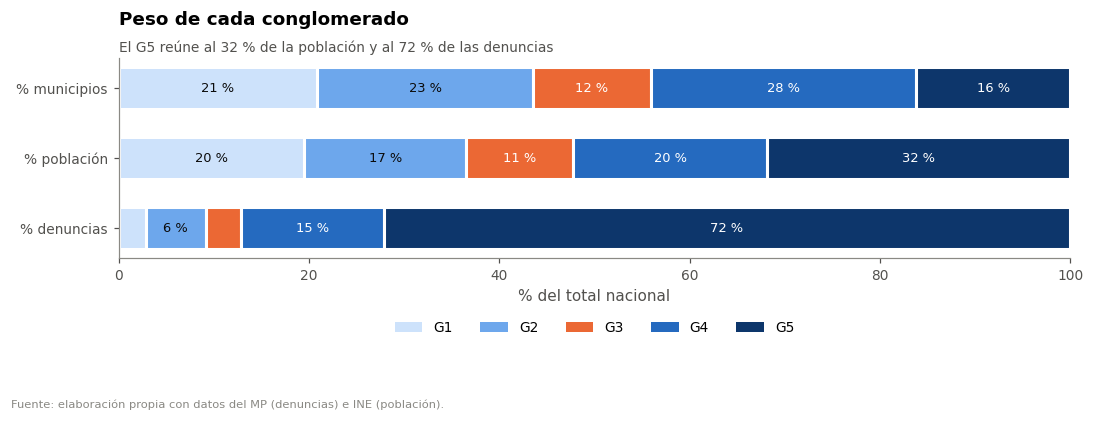

In [3]:
def tasa_agregada(cont, expo):
    """Tasa del grupo = Σ denuncias / Σ persona-años × 100 mil (no el promedio de tasas)."""
    return cont.sum() / expo.sum() * 1e5

peso = pd.DataFrame({
    "municipios": grupo.value_counts().sort_index(),
    "población promedio": base.groupby(grupo)["Poblacion_prom"].sum(),
    "denuncias 2022-2025": base.groupby(grupo)["Denuncias_total"].sum(),
})
peso["% municipios"] = peso["municipios"] / 340 * 100
peso["% población"] = peso["población promedio"] / peso["población promedio"].sum() * 100
peso["% denuncias"] = peso["denuncias 2022-2025"] / peso["denuncias 2022-2025"].sum() * 100
peso["tasa total (x100 mil/año)"] = [tasa_agregada(base.loc[grupo == g, "Denuncias_total"],
                                                   exposicion[grupo == g]) for g in GRUPOS]
peso["población mediana municipal"] = base.groupby(grupo)["Poblacion_prom"].median()
display(peso)

fig, ax = plt.subplots(figsize=(10, 3.8))
cats = ["% municipios", "% población", "% denuncias"]
izq = np.zeros(3)
for g in GRUPOS:
    v = peso.loc[g, cats].values
    ax.barh(cats, v, left=izq, color=COLOR_CLUSTER[g], edgecolor="white", linewidth=2, height=0.6)
    for i, (x, w) in enumerate(zip(izq, v)):
        if w >= 5:
            ax.text(x + w / 2, i, f"{w:.0f} %", ha="center", va="center", fontsize=8.5,
                    color="white" if g in (4, 5, 3) else COLOR["texto"])
    izq += v
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_xlabel("% del total nacional")
ax.set_title("Peso de cada conglomerado")
subtitulo(ax, "El G5 reúne al 32 % de la población y al 72 % de las denuncias")
ax.legend([Patch(color=COLOR_CLUSTER[g]) for g in GRUPOS], [f"G{g}" for g in GRUPOS],
          ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.45))
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "01_peso_conglomerados", CARPETA_FIG)
plt.show()

## 3. Tasas reales por 100 mil habitantes

Para cada grupo se calcula la **tasa agregada** (suma de denuncias del grupo / suma de su población × 100 mil) y el **índice respecto a la tasa nacional** (1 = igual a la nacional; 2 = el doble; 0.5 = la mitad). También se reporta la **mediana** de las tasas municipales, que no se ve afectada por los municipios extremos.

In [4]:
tasa_grupo = pd.DataFrame({g: tasa_agregada(conteos[grupo == g], exposicion[grupo == g]) for g in GRUPOS})
tasa_nac = tasa_agregada(conteos, exposicion)
indice = tasa_grupo.div(tasa_nac, axis=0)
mediana = tasas.groupby(grupo).median().T

tabla_tasas = tasa_grupo.copy()
tabla_tasas.columns = [f"G{g}" for g in GRUPOS]
tabla_tasas["Nacional"] = tasa_nac
print("Tasa agregada por 100 mil habitantes al año (2022–2025)")
display(tabla_tasas.rename(index=CODIGO_A_CORTO).round(1))
print("Índice respecto a la tasa nacional")
display(indice.set_axis([f"G{g}" for g in GRUPOS], axis=1).rename(index=CODIGO_A_CORTO).round(2))
print("Mediana de las tasas municipales")
display(mediana.set_axis([f"G{g}" for g in GRUPOS], axis=1).rename(index=CODIGO_A_CORTO).round(1))

Tasa agregada por 100 mil habitantes al año (2022–2025)


,G1,G2,G3,G4,G5,Nacional
Homicidio,3.00,4.10,22.20,20.30,36.40,19.50
Asesinato,0.70,0.80,3.50,2.70,11.40,4.80
Robo,7.20,23.10,14.40,40.60,225.40,87.00
Robo agravado,5.50,15.90,16.50,54.80,237.30,92.40
Hurto,23.00,69.30,42.30,106.40,367.20,159.70
Hurto agravado,7.80,24.10,33.20,68.70,200.60,87.20
Extorsión,14.10,54.90,30.40,110.40,255.40,119.30
Violación,17.90,19.60,30.00,27.00,30.10,25.30
Violación agravada,4.60,2.80,1.50,3.10,2.90,3.10
Violación c. esp. agrav.,2.40,0.90,0.40,1.00,1.10,1.20


Índice respecto a la tasa nacional


,G1,G2,G3,G4,G5
Homicidio,0.15,0.21,1.14,1.04,1.87
Asesinato,0.14,0.16,0.72,0.57,2.35
Robo,0.08,0.27,0.16,0.47,2.59
Robo agravado,0.06,0.17,0.18,0.59,2.57
Hurto,0.14,0.43,0.27,0.67,2.30
Hurto agravado,0.09,0.28,0.38,0.79,2.30
Extorsión,0.12,0.46,0.25,0.93,2.14
Violación,0.71,0.78,1.19,1.07,1.19
Violación agravada,1.49,0.90,0.47,0.99,0.94
Violación c. esp. agrav.,1.98,0.73,0.35,0.85,0.87


Mediana de las tasas municipales


,G1,G2,G3,G4,G5
Homicidio,2.00,3.40,20.00,15.40,24.60
Asesinato,0.40,0.00,2.90,2.10,7.70
Robo,6.70,18.20,10.10,25.20,76.60
Robo agravado,3.60,13.10,16.00,49.10,121.30
Hurto,21.40,60.50,43.20,87.50,193.60
Hurto agravado,6.20,21.10,32.90,62.40,133.60
Extorsión,12.40,58.90,26.10,113.00,200.40
Violación,15.90,15.90,31.70,23.20,30.20
Violación agravada,3.30,2.30,1.60,2.30,2.80
Violación c. esp. agrav.,1.00,0.40,0.00,0.90,1.10


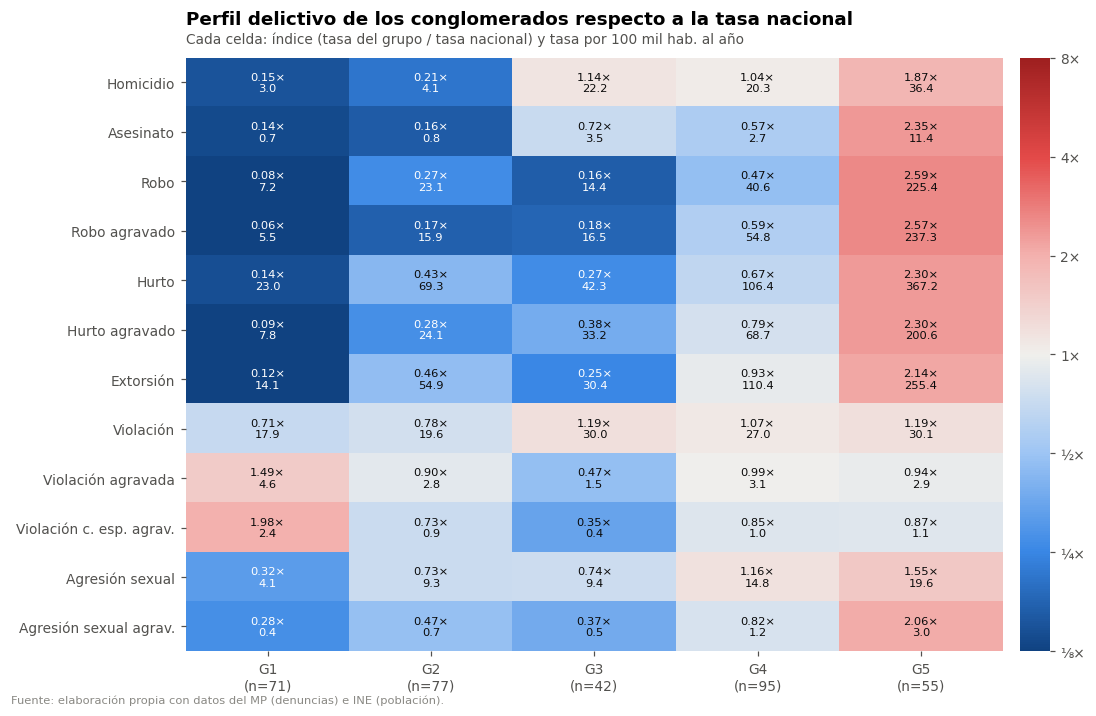

In [5]:
fig, ax = plt.subplots(figsize=(10, 6.5))
log_idx = np.log2(indice.values)
im = ax.imshow(log_idx, cmap=CMAP_DIVERGENTE, vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(5), [f"G{g}\n(n={peso.loc[g, 'municipios']})" for g in GRUPOS])
ax.set_yticks(range(12), [CODIGO_A_CORTO[c] for c in CODIGOS_DELITO])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(12):
    for j in range(5):
        v = indice.values[i, j]
        ax.text(j, i, f"{v:.2f}×\n{tasa_grupo.values[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(np.log2(v)) > 1.6 else COLOR["texto"])
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_yticklabels(["⅛×", "¼×", "½×", "1×", "2×", "4×", "8×"])
cb.outline.set_visible(False)
ax.set_title("Perfil delictivo de los conglomerados respecto a la tasa nacional")
subtitulo(ax, "Cada celda: índice (tasa del grupo / tasa nacional) y tasa por 100 mil hab. al año")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "02_perfil_indice_nacional", CARPETA_FIG)
plt.show()

## 4. Mezcla de delitos de cada grupo

Qué **proporción** de las denuncias de cada grupo corresponde a cada familia de delitos. Aquí no importa el nivel, sino la **composición**.

,Contra la vida,Contra el patrimonio,Extorsión,Sexuales
grupo,,,,
1,4.00,48.00,15.50,32.40
2,2.20,58.70,24.30,14.80
3,12.50,52.10,14.90,20.50
4,5.10,60.00,24.50,10.40
5,3.40,74.10,18.40,4.10
Nacional,4.00,69.50,19.40,7.10


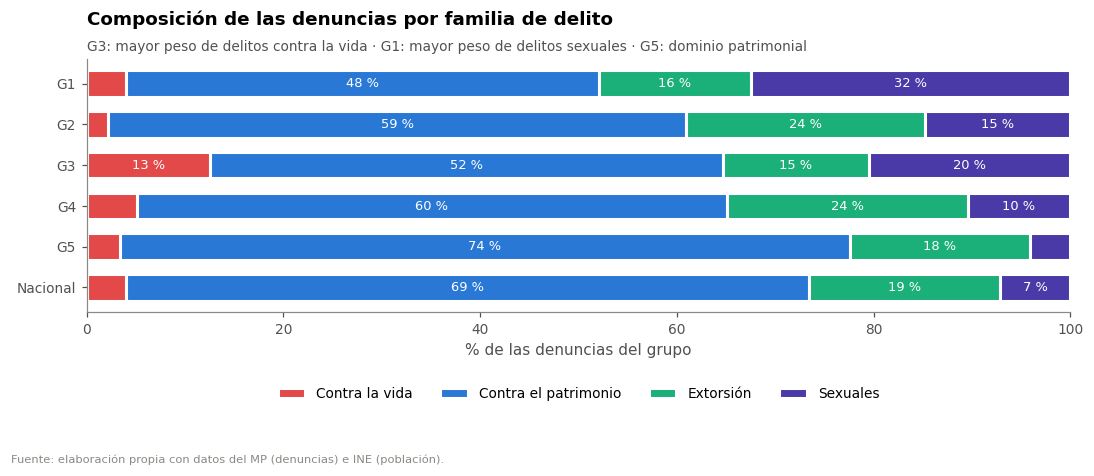

In [6]:
familias = ["Contra la vida", "Contra el patrimonio", "Extorsión", "Sexuales"]
mezcla = pd.DataFrame({f: conteos[[c for c in CODIGOS_DELITO if FAMILIA_COD[c] == f]].sum(axis=1)
                       for f in familias}).groupby(grupo).sum()
mezcla_pct = mezcla.div(mezcla.sum(axis=1), axis=0) * 100
nacional_pct = mezcla.sum() / mezcla.values.sum() * 100
mezcla_pct.loc["Nacional"] = nacional_pct
display(mezcla_pct.round(1))

col_fam = {"Contra la vida": COLOR["rojo"], "Contra el patrimonio": COLOR["azul"],
           "Extorsión": COLOR["aqua"], "Sexuales": COLOR["violeta"]}
fig, ax = plt.subplots(figsize=(10, 4.3))
etiquetas = [f"G{g}" for g in GRUPOS] + ["Nacional"]
izq = np.zeros(len(etiquetas))
for f in familias:
    v = mezcla_pct[f].values
    ax.barh(etiquetas, v, left=izq, color=col_fam[f], edgecolor="white", linewidth=2, height=0.65, label=f)
    for i, (x, w) in enumerate(zip(izq, v)):
        if w >= 6:
            ax.text(x + w / 2, i, f"{w:.0f} %", ha="center", va="center", fontsize=8.5, color="white")
    izq += v
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_xlabel("% de las denuncias del grupo")
ax.set_title("Composición de las denuncias por familia de delito")
subtitulo(ax, "G3: mayor peso de delitos contra la vida · G1: mayor peso de delitos sexuales · G5: dominio patrimonial")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.4))
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "03_mezcla_delitos", CARPETA_FIG)
plt.show()

## 5. Magnitud de las diferencias entre grupos

> **Advertencia metodológica importante.** K-means forma los grupos precisamente para que sean **distintos entre sí** en estas mismas variables. Por eso, una prueba de hipótesis que compare los grupos casi siempre dará un p-valor muy pequeño **por construcción**: es un razonamiento circular (*double dipping*; Kriegeskorte et al., 2009). En este notebook las pruebas **no se usan para validar** los grupos. Esa validación ya se hizo con criterios independientes de la partición: estabilidad bootstrap, concordancia entre algoritmos (notebooks 06 y 07) y coherencia espacial (sección 9.3).
>
> Aquí se usan de forma **descriptiva**, para responder **en qué delitos** se diferencian más los grupos y con qué magnitud. Lo que se interpreta es el **tamaño del efecto**, no el p-valor.

### 5.1 Tamaño de las diferencias por delito (Kruskal-Wallis)

Se usa el estadístico **H de Kruskal-Wallis** (no paramétrico, porque las tasas son asimétricas) para calcular el **tamaño del efecto** $\varepsilon^2 = \frac{H - k + 1}{n - k}$: la proporción de la variación en rangos de cada delito que se asocia al grupo. Referencias: 0.01 pequeño, 0.08 mediano, ≥ 0.26 grande (Tomczak y Tomczak, 2014).

In [7]:
filas = []
for c in CODIGOS_DELITO:
    muestras = [tasas.loc[grupo == g, c] for g in GRUPOS]
    H, p = stats.kruskal(*muestras)
    eps2 = (H - 5 + 1) / (340 - 5)
    filas.append({"delito": CODIGO_A_CORTO[c], "H": H, "p_valor": p, "épsilon²": eps2,
                  "efecto": "grande" if eps2 >= 0.26 else "mediano" if eps2 >= 0.08 else "pequeño"})
kw = pd.DataFrame(filas).set_index("delito").sort_values("épsilon²", ascending=False)
kw = kw.rename(columns={"p_valor": "p (solo referencial)"})
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
display(kw)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

,H,p (solo referencial),épsilon²,efecto
delito,,,,
Hurto agravado,264,5.38e-56,0.777,grande
Robo agravado,256,4.19e-54,0.751,grande
Extorsión,250,5.1e-53,0.736,grande
Hurto,242,3.92e-51,0.71,grande
Robo,217,6.93e-46,0.637,grande
Homicidio,204,6.49e-43,0.596,grande
Agresión sexual,196,2.83e-41,0.573,grande
Asesinato,178,2.02e-37,0.519,grande
Agresión sexual agrav.,83.6,3.06e-17,0.237,mediano


### 5.2 ¿El G3 es realmente distinto? Comparaciones por pares

El perfil más novedoso es el del **G3**, con violencia letal en el nivel nacional pero pocos delitos patrimoniales. Se compara con sus vecinos en intensidad (G2 y G4) mediante la prueba de **Mann-Whitney** con corrección de **Holm**. Con la advertencia de la sección 5, lo relevante es la **dirección y la magnitud** de cada diferencia (qué distingue al G3 y qué **no** lo distingue), no demostrar que el grupo existe. El tamaño del efecto es la **correlación biserial por rangos** $r = \frac{2U}{n_1 n_2} - 1$ (positiva: el G3 es mayor).

In [8]:
comparaciones = []
for otro in [2, 4]:
    for c in ["homicidio", "asesinato", "violacion", "robo", "hurto", "extorsion"]:
        a, b = tasas.loc[grupo == 3, c], tasas.loc[grupo == otro, c]
        U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        comparaciones.append({"comparación": f"G3 vs G{otro}", "delito": CODIGO_A_CORTO[c],
                              "mediana G3": a.median(), "mediana del otro grupo": b.median(),
                              "r (efecto)": 2 * U / (len(a) * len(b)) - 1,   # + : G3 mayor
                              "p": p})
comp = pd.DataFrame(comparaciones)
orden_p = np.argsort(comp["p"].values)
m = len(comp)
ajustado = np.empty(m)
acumulado = 0
for rango, i in enumerate(orden_p):
    acumulado = max(acumulado, min(1, (m - rango) * comp["p"].values[i]))
    ajustado[i] = acumulado
comp["p Holm"] = ajustado
comp["dirección"] = np.where(comp["r (efecto)"] > 0, "G3 mayor", "G3 menor")
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
display(comp.drop(columns="p"))
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

,comparación,delito,mediana G3,mediana del otro grupo,r (efecto),p Holm,dirección
0,G3 vs G2,Homicidio,20,3.41,0.899,6.8e-15,G3 mayor
1,G3 vs G2,Asesinato,2.88,0,0.714,3.68e-10,G3 mayor
2,G3 vs G2,Violación,31.7,15.9,0.581,1.22e-06,G3 mayor
3,G3 vs G2,Robo,10.1,18.2,-0.544,5.03e-06,G3 menor
4,G3 vs G2,Hurto,43.2,60.5,-0.504,2.37e-05,G3 menor
5,G3 vs G2,Extorsión,26.1,58.9,-0.573,1.59e-06,G3 menor
6,G3 vs G4,Homicidio,20,15.4,0.173,0.134,G3 mayor
7,G3 vs G4,Asesinato,2.88,2.07,0.196,0.134,G3 mayor
8,G3 vs G4,Violación,31.7,23.2,0.325,0.0074,G3 mayor
9,G3 vs G4,Robo,10.1,25.2,-0.704,4.4e-10,G3 menor


### 5.3 Distribución municipal de los delitos que definen los perfiles

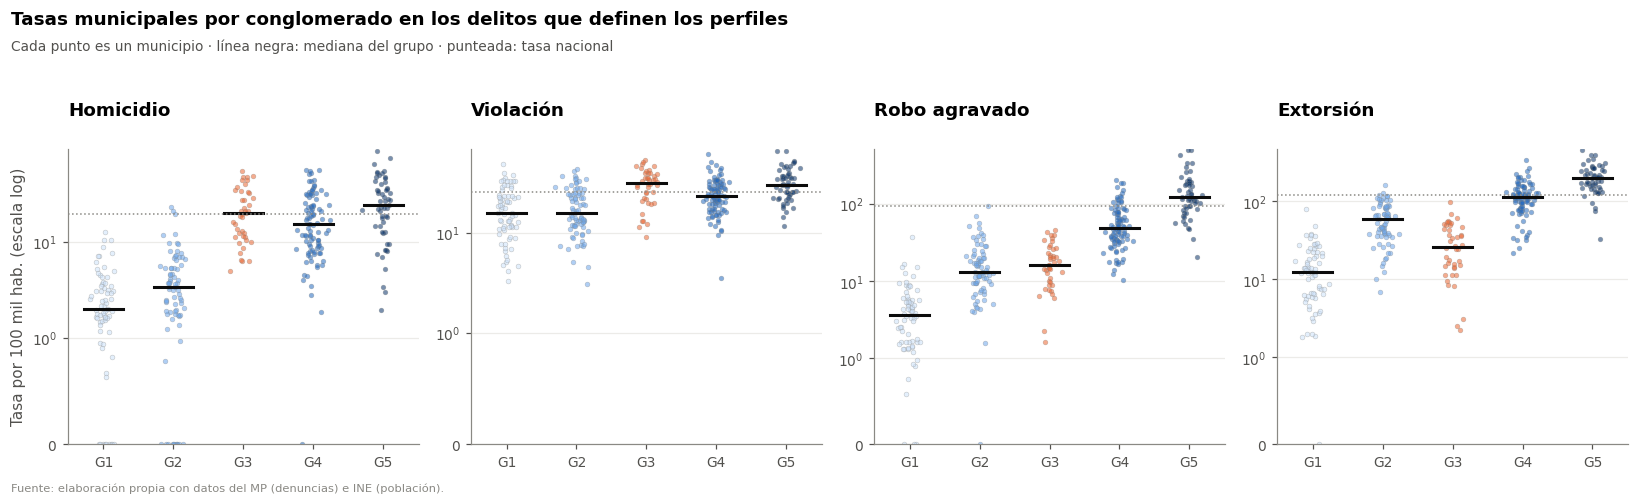

In [9]:
clave = ["homicidio", "violacion", "robo_agravado", "extorsion"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
rng = np.random.default_rng(0)
for ax, c in zip(axes, clave):
    for g in GRUPOS:
        v = tasas.loc[grupo == g, c]
        ax.scatter(rng.normal(g, 0.08, len(v)), v, s=10, alpha=0.55, color=COLOR_CLUSTER[g],
                   edgecolor=COLOR["gris"], linewidth=0.3)
        ax.plot([g - 0.28, g + 0.28], [v.median()] * 2, color=COLOR["texto"], linewidth=2)
    ax.axhline(tasa_nac[c], color=COLOR["gris"], linestyle=":", linewidth=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_xticks(GRUPOS, [f"G{g}" for g in GRUPOS])
    ax.grid(axis="x", visible=False)
    ax.set_title(CODIGO_A_CORTO[c])
axes[0].set_ylabel("Tasa por 100 mil hab. (escala log)")
fig.suptitle("Tasas municipales por conglomerado en los delitos que definen los perfiles", x=0.01,
             ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.9, "Cada punto es un municipio · línea negra: mediana del grupo · punteada: tasa nacional",
         fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
guardar_figura(fig, "04_distribucion_delitos_clave", CARPETA_FIG)
plt.show()

## 6. Evolución 2022–2025 por grupo

Tasa agregada anual de cada grupo (grupo fijo, calculado con el periodo completo).

Variación 2022–2025 de la tasa agregada (%)


,Total (12 delitos),Homicidio + asesinato,Extorsión,Robo + hurto (4 tipos)
G1,-15.00,0.80,78.50,-29.50
G2,4.90,2.30,126.40,-16.30
G3,-6.30,27.60,60.80,-17.80
G4,1.90,-2.40,128.70,-20.00
G5,-8.00,-2.00,53.00,-17.80


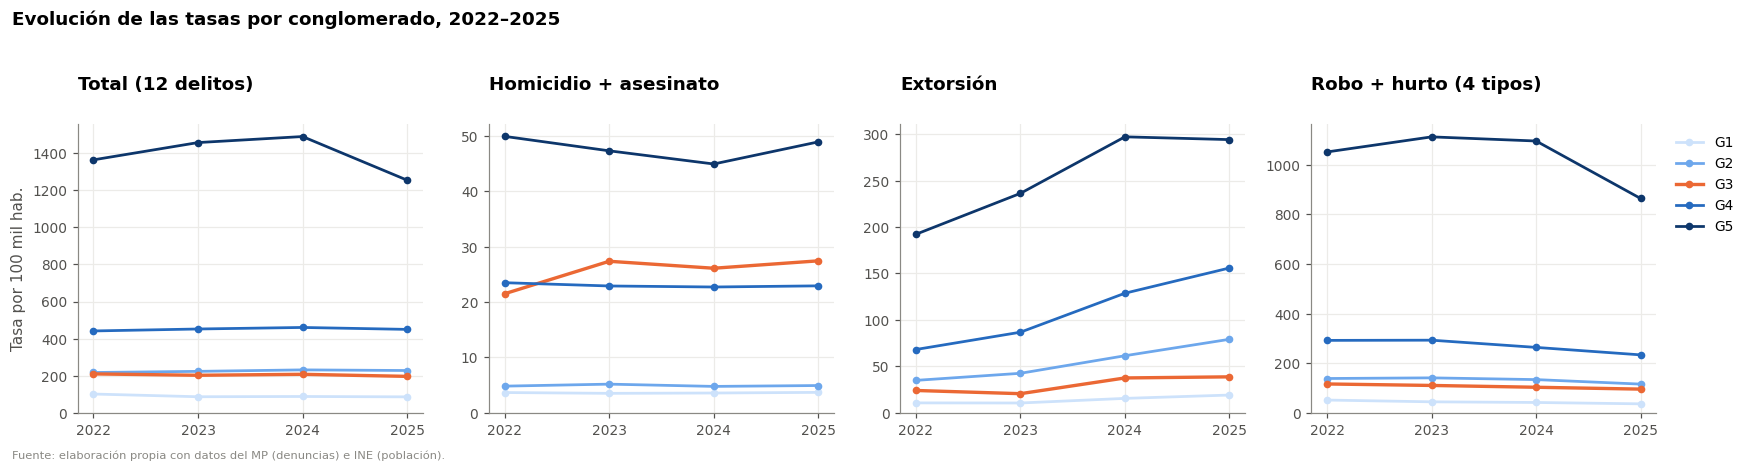

In [10]:
anual = denuncias.assign(grupo=denuncias["Codigo_Municipio"].map(grupo))
pob_anual = poblacion.assign(grupo=poblacion["Codigo_Municipio"].map(grupo)).groupby(["grupo", "Anio"])["Poblacion"].sum()

def serie(filtro=None):
    d = anual if filtro is None else anual[anual["Codigo_Delito"].isin(filtro)]
    return (d.groupby(["grupo", "Anio"])["Denuncias"].sum() / pob_anual * 1e5).unstack("grupo")

paneles = {"Total (12 delitos)": None, "Homicidio + asesinato": ["homicidio", "asesinato"],
           "Extorsión": ["extorsion"], "Robo + hurto (4 tipos)": ["robo", "robo_agravado", "hurto", "hurto_agravado"]}
series = {t: serie(f) for t, f in paneles.items()}
var = pd.DataFrame({t: (s.loc[2025] / s.loc[2022] - 1) * 100 for t, s in series.items()})
var.index = [f"G{g}" for g in var.index]
print("Variación 2022–2025 de la tasa agregada (%)")
display(var.round(1))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (titulo, s) in zip(axes, series.items()):
    for g in GRUPOS:
        ax.plot(s.index, s[g], marker="o", markersize=4, color=COLOR_CLUSTER[g], label=f"G{g}",
                linewidth=2.2 if g == 3 else 1.8)
    ax.set_xticks(ANIOS_ESTUDIO)
    ax.set_title(titulo)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Tasa por 100 mil hab.")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Evolución de las tasas por conglomerado, 2022–2025", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "05_evolucion_conglomerados", CARPETA_FIG)
plt.show()

## 7. Municipios representativos y de frontera

- **Representativos:** los 3 más cercanos al centroide de su grupo, es decir, los que mejor encarnan el perfil.
- **De frontera:** silueta negativa; su perfil está entre dos grupos. No es un error: es esperable en un continuo, y conviene mencionarlo al interpretar el mapa.

In [11]:
res = resultado.join(base[["Poblacion_prom", "Tasa_total"]])
representativos = (res.sort_values("distancia_centroide").groupby("grupo").head(3)
                   .sort_values(["grupo", "distancia_centroide"]))
display(representativos[["grupo", "Departamento", "Municipio", "Poblacion_prom", "Tasa_total", "distancia_centroide"]])
frontera = res[res["silueta"] < 0].sort_values("silueta")
print(f"Municipios de frontera (silueta < 0): {len(frontera)}")
display(frontera[["grupo", "Departamento", "Municipio", "silueta"]])

,grupo,Departamento,Municipio,Poblacion_prom,Tasa_total,distancia_centroide
Codigo_Municipio,,,,,,
1608,1,Alta Verapaz,Senahú,"102,020.00",89.93,0.97
1208,1,San Marcos,Sibinal,"17,523.50",72.76,1.00
1416,1,Quiché,Sacapulas,"56,694.50",97.45,1.03
109,2,Guatemala,San Pedro Sacatepéquez,"57,766.25",193.88,0.82
1213,2,San Marcos,El Tumbador,"54,327.00",215.82,1.06
1502,2,Baja Verapaz,San Miguel Chicaj,"39,243.75",252.91,1.19
2107,3,Jalapa,Mataquescuintla,"48,546.50",230.71,1.16
1614,3,Alta Verapaz,Chahal,"31,134.50",207.17,1.35
1713,3,Petén,Las Cruces,"40,141.75",187.46,1.37


Municipios de frontera (silueta < 0): 8


,grupo,Departamento,Municipio,silueta
Codigo_Municipio,,,,
1617,3,Alta Verapaz,Raxruhá,-0.04
1224,1,San Marcos,San José Ojetenam,-0.02
1223,1,San Marcos,Ixchiguán,-0.02
1012,5,Suchitepéquez,San Gabriel,-0.01
610,2,Santa Rosa,Santa María Ixhuatán,-0.01
1015,2,Suchitepéquez,Santa Bárbara,-0.01
924,1,Quetzaltenango,Palestina de Los Altos,-0.00
714,3,Sololá,Santa Cruz La Laguna,-0.00


## 8. Nombres de los conglomerados

### 8.1 Criterios para nombrar

Un buen nombre de conglomerado debe ser:

1. **Basado en evidencia:** describe lo que muestran las tasas reales, no una expectativa previa.
2. **Distintivo:** dice qué separa a ese grupo de los demás, no solo su nivel.
3. **Neutral:** describe **patrones de denuncia**, no "peligrosidad" ni características de la población (ver consideraciones del README).
4. **Breve y consistente:** todos los nombres siguen la misma lógica.
5. **Verificable:** cada nombre tiene condiciones numéricas que el código comprueba.

### 8.2 Los ejes que realmente distinguen a los grupos

Las secciones 3 y 4 muestran que los 12 delitos se mueven en **bloques**. Se agrupan en cuatro dimensiones y se calcula el **índice respecto a la tasa nacional** de cada una (tasa agregada del grupo / tasa nacional; 1 = igual al país):

| Dimensión | Delitos |
|---|---|
| **Patrimonial y extorsiva** | robo, robo agravado, hurto, hurto agravado, extorsión |
| **Violencia letal** | homicidio, asesinato |
| **Violencia sexual** | violación (3 tipos), agresión sexual (2 tipos) |
| **Total** | los 12 delitos |

In [12]:
DIMENSIONES = {
    "Patrimonial y extorsiva": ["robo", "robo_agravado", "hurto", "hurto_agravado", "extorsion"],
    "Violencia letal": ["homicidio", "asesinato"],
    "Violencia sexual": ["violacion", "violacion_agravada", "violacion_circ_especiales",
                         "agresion_sexual", "agresion_sexual_agravada"],
    "Total": CODIGOS_DELITO,
}

def indice_dimension(cols, por=grupo):
    """Índice de la tasa agregada de un conjunto de delitos respecto a la nacional."""
    n = conteos[cols].sum(axis=1)
    nacional = n.sum() / exposicion.sum()
    if por is None:                                   # índice por municipio
        return (n / exposicion) / nacional
    return (n.groupby(por).sum() / exposicion.groupby(por).sum()) / nacional

ejes = pd.DataFrame({d: indice_dimension(c) for d, c in DIMENSIONES.items()})
ejes.index = [f"G{g}" for g in ejes.index]
display(ejes.round(2))

amplitud = (ejes.drop(columns="Total").max() / ejes.drop(columns="Total").min()).round(1)
print("Cuántas veces varía el índice entre el grupo más alto y el más bajo:")
print(amplitud.to_string())

,Patrimonial y extorsiva,Violencia letal,Violencia sexual,Total
G1,0.11,0.15,0.67,0.15
G2,0.34,0.20,0.76,0.37
G3,0.25,1.05,0.96,0.33
G4,0.70,0.95,1.08,0.73
G5,2.36,1.96,1.30,2.27


Cuántas veces varía el índice entre el grupo más alto y el más bajo:
Patrimonial y extorsiva   22.30
Violencia letal           13.20
Violencia sexual           1.90


**Lectura:**

- La dimensión **patrimonial y extorsiva** separa a los grupos de forma muy marcada: de 0.11× a 2.36×, unas 22 veces entre el más bajo y el más alto.
- La **violencia letal** también los separa (de 0.15× a 1.96×, unas 13 veces) y, lo más importante, **no sigue el mismo orden**: el G3 tiene poca criminalidad patrimonial pero violencia letal igual a la nacional.
- La **violencia sexual** varía poco (de 0.67× a 1.30×, menos de 2 veces). Casi no distingue a los grupos, así que no se usa en los nombres, solo en las descripciones.

Los conglomerados forman, por lo tanto, una **tipología en dos ejes**: la criminalidad patrimonial y extorsiva frente a la violencia letal.

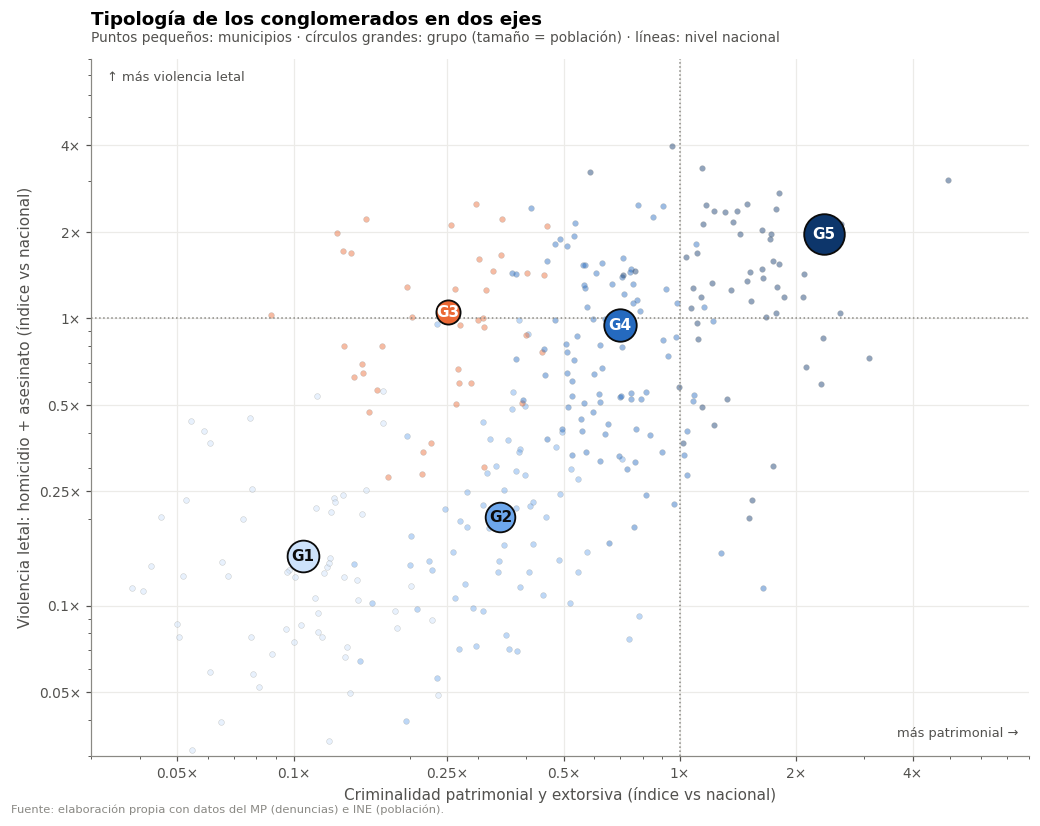

In [13]:
ind_mun_x = indice_dimension(DIMENSIONES["Patrimonial y extorsiva"], por=None)
ind_mun_y = indice_dimension(DIMENSIONES["Violencia letal"], por=None)
piso = 0.02                                          # para mostrar en escala log los municipios con 0

fig, ax = plt.subplots(figsize=(9.5, 7.5))
ax.axvline(1, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.axhline(1, color=COLOR["gris"], linestyle=":", linewidth=1)
for g in GRUPOS:
    sel = grupo == g
    ax.scatter(ind_mun_x[sel].clip(lower=piso), ind_mun_y[sel].clip(lower=piso), s=14, alpha=0.45,
               color=COLOR_CLUSTER[g], edgecolor=COLOR["gris"], linewidth=0.3)
for g in GRUPOS:
    x, y = ejes.loc[f"G{g}", "Patrimonial y extorsiva"], ejes.loc[f"G{g}", "Violencia letal"]
    ax.scatter(x, y, s=peso.loc[g, "población promedio"] / 8000, color=COLOR_CLUSTER[g],
               edgecolor=COLOR["texto"], linewidth=1.2, zorder=4)
    ax.annotate(f"G{g}", (x, y), ha="center", va="center", fontsize=10, fontweight="bold", zorder=5,
                color="white" if g in (3, 4, 5) else COLOR["texto"])
ax.set_xscale("log"); ax.set_yscale("log")
ticks = [0.05, 0.1, 0.25, 0.5, 1, 2, 4]
ax.set_xticks(ticks, [f"{t:g}×" for t in ticks]); ax.set_yticks(ticks, [f"{t:g}×" for t in ticks])
ax.set_xlim(0.03, 8); ax.set_ylim(0.03, 8)
ax.set_xlabel("Criminalidad patrimonial y extorsiva (índice vs nacional)")
ax.set_ylabel("Violencia letal: homicidio + asesinato (índice vs nacional)")
ax.text(7.5, 0.035, "más patrimonial →", ha="right", fontsize=8.5, color=COLOR["texto_sec"])
ax.text(0.033, 7.3, "↑ más violencia letal", fontsize=8.5, color=COLOR["texto_sec"], va="top")
ax.set_title("Tipología de los conglomerados en dos ejes")
subtitulo(ax, "Puntos pequeños: municipios · círculos grandes: grupo (tamaño = población) · líneas: nivel nacional")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "09_tipologia_dos_ejes", CARPETA_FIG)
plt.show()

### 8.3 Nombres asignados

Cada nombre se construye con la misma lógica: **nivel general** + **rasgo que lo distingue** en los dos ejes.

| Grupo | Patrimonial y extorsiva | Violencia letal | Nombre |
|---|---|---|---|
| G1 | muy baja (0.11×) | muy baja (0.15×) | **Baja incidencia general** |
| G2 | baja (0.34×) | muy baja (0.20×) | **Predominio patrimonial con baja violencia letal** |
| G3 | baja (0.25×) | **nacional (1.05×)** | **Violencia letal con baja criminalidad patrimonial** |
| G4 | cercana a la nacional (0.70×) | nacional (0.95×) | **Incidencia intermedia** |
| G5 | **alta (2.36×)** | **alta (1.96×)** | **Alta incidencia generalizada** |

**Por qué estos nombres y no otros:**

- **G2 frente a G1:** ambos tienen poca violencia letal. El G2 tiene **3 veces más** criminalidad patrimonial y extorsiva que el G1, y esos delitos son el **83 %** de sus denuncias. Se evita llamarlo "moderado", porque sus tasas siguen **por debajo** de la nacional.
- **G3:** se evita "violencia" a secas, porque el G5 tiene **más** homicidios en términos absolutos. Lo que lo define es la **combinación**: violencia letal en el nivel nacional **sin** la criminalidad patrimonial que la acompaña en el G4 y el G5. Así el nombre no se contradice con los datos.
- **G4:** todos sus índices están entre 0.6× y 1.1×. Es el grupo que **más se parece al promedio del país**, y "intermedia" lo describe sin inventar un rasgo que no tiene.
- **G5:** supera 1.3× en las cuatro dimensiones, incluida la violencia sexual; de ahí "generalizada".

In [14]:
NOMBRE_CLUSTER = {
    1: "Baja incidencia general",
    2: "Predominio patrimonial con baja violencia letal",
    3: "Violencia letal con baja criminalidad patrimonial",
    4: "Incidencia intermedia",
    5: "Alta incidencia generalizada",
}
NOMBRE_CORTO_CLUSTER = {1: "Baja incidencia", 2: "Patrimonial, baja violencia", 3: "Violencia letal",
                        4: "Intermedia", 5: "Alta incidencia"}
DESCRIPCION_CLUSTER = {
    1: "Tasas muy por debajo de la nacional en casi todos los delitos (0.1–0.3×). Los delitos sexuales pesan "
       "relativamente más en su mezcla (32 %). Predomina en el altiplano occidental.",
    2: "Tasas por debajo de la nacional, pero con 3 veces más robos, hurtos y extorsión que el G1; estos delitos son "
       "el 83 % de sus denuncias. Violencia letal muy baja (0.2×).",
    3: "Homicidio y asesinato en el nivel nacional (1.05×) y violación por encima (1.19×), con robos, hurtos y "
       "extorsión muy bajos (0.25×). Mayor peso de delitos contra la vida (13 %). Norte y oriente del país.",
    4: "Índices entre 0.6× y 1.1× en todas las dimensiones: el perfil más cercano al promedio del país, sin un delito "
       "dominante.",
    5: "Entre 2 y 2.6 veces la tasa nacional en robos, hurtos y extorsión, y casi el doble en violencia letal. "
       "Concentra el 72 % de las denuncias. Corredor central y costa sur.",
}

e = ejes
verificaciones = {
    "G1: patrimonial-extorsiva y violencia letal < 0.2×":
        (e.loc["G1", ["Patrimonial y extorsiva", "Violencia letal"]] < 0.2).all(),
    "G2: patrimonial-extorsiva entre 0.25× y 0.6×, y ≥ 2 veces la del G1":
        0.25 <= e.loc["G2", "Patrimonial y extorsiva"] <= 0.6
        and e.loc["G2", "Patrimonial y extorsiva"] >= 2 * e.loc["G1", "Patrimonial y extorsiva"],
    "G2: violencia letal < 0.3×": e.loc["G2", "Violencia letal"] < 0.3,
    "G2: > 80 % de sus denuncias son patrimoniales o extorsión":
        mezcla_pct.loc[2, ["Contra el patrimonio", "Extorsión"]].sum() > 80,
    "G3: violencia letal ≥ 0.9× (nivel nacional o más)": e.loc["G3", "Violencia letal"] >= 0.9,
    "G3: patrimonial-extorsiva < 0.4×": e.loc["G3", "Patrimonial y extorsiva"] < 0.4,
    "G3: mayor razón violencia letal / patrimonial de los 5 grupos":
        (e["Violencia letal"] / e["Patrimonial y extorsiva"]).idxmax() == "G3",
    "G4: las 4 dimensiones entre 0.6× y 1.2×": e.loc["G4"].between(0.6, 1.2).all(),
    "G5: las 4 dimensiones > 1.25×": (e.loc["G5"] > 1.25).all(),
}
tabla_ver = pd.Series(verificaciones, name="se cumple").to_frame()
display(tabla_ver)
assert tabla_ver["se cumple"].all(), "Algún nombre no se sostiene con los datos: revisar"

resumen_nombres = pd.DataFrame({"nombre": NOMBRE_CLUSTER, "nombre corto": NOMBRE_CORTO_CLUSTER,
                                "municipios": peso["municipios"], "% población": peso["% población"].round(1),
                                "tasa total": peso["tasa total (x100 mil/año)"].round(0)})
resumen_nombres.index = [f"G{g}" for g in resumen_nombres.index]
display(resumen_nombres)

,se cumple
G1: patrimonial-extorsiva y violencia letal < 0.2×,True
"G2: patrimonial-extorsiva entre 0.25× y 0.6×, y ≥ 2 veces la del G1",True
G2: violencia letal < 0.3×,True
G2: > 80 % de sus denuncias son patrimoniales o extorsión,True
G3: violencia letal ≥ 0.9× (nivel nacional o más),True
G3: patrimonial-extorsiva < 0.4×,True
G3: mayor razón violencia letal / patrimonial de los 5 grupos,True
G4: las 4 dimensiones entre 0.6× y 1.2×,True
G5: las 4 dimensiones > 1.25×,True


,nombre,nombre corto,municipios,% población,tasa total
G1,Baja incidencia general,Baja incidencia,71,19.50,91.00
G2,Predominio patrimonial con baja violencia letal,"Patrimonial, baja violencia",77,17.00,225.00
G3,Violencia letal con baja criminalidad patrimonial,Violencia letal,42,11.30,204.00
G4,Incidencia intermedia,Intermedia,95,20.40,451.00
G5,Alta incidencia generalizada,Alta incidencia,55,31.90,"1,390.00"


## 9. Composición territorial y mapa

### 9.1 ¿En qué departamentos está cada grupo?

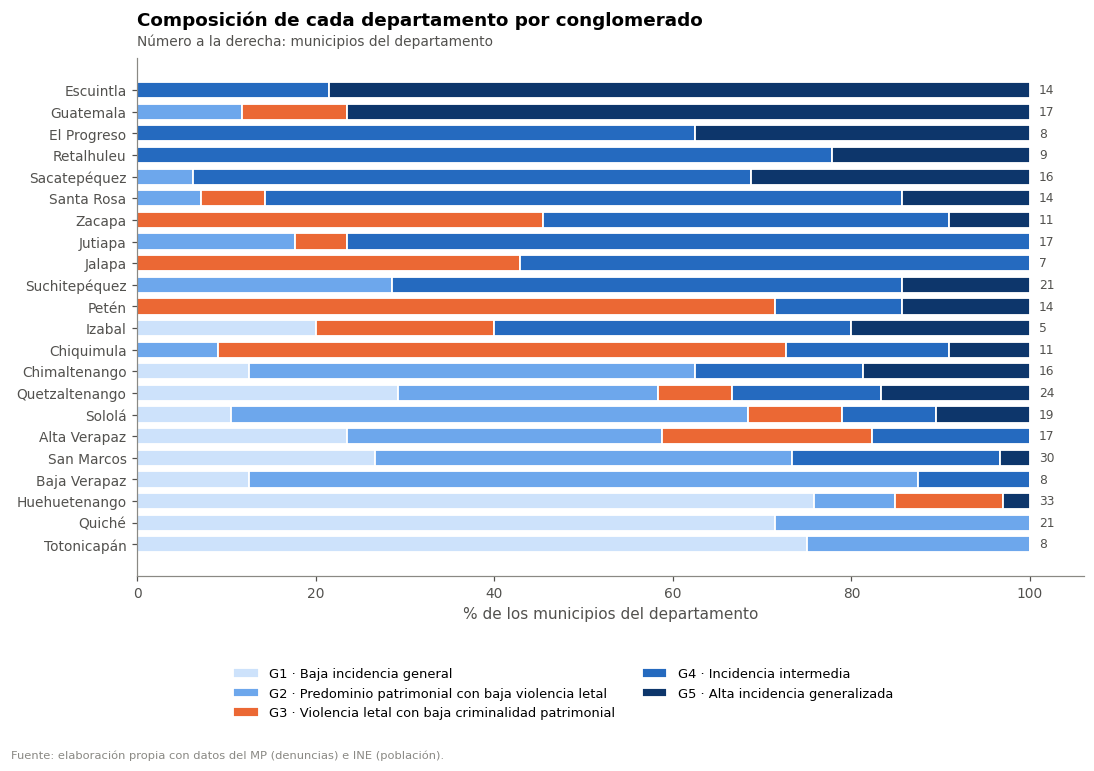

In [15]:
depto = pd.crosstab(base["Departamento"], grupo)
depto_pct = depto.div(depto.sum(axis=1), axis=0) * 100
orden_dep = (depto_pct * np.array(GRUPOS)).sum(axis=1).sort_values().index   # por intensidad promedio

fig, ax = plt.subplots(figsize=(10, 7))
izq = np.zeros(len(orden_dep))
for g in GRUPOS:
    v = depto_pct.loc[orden_dep, g].values
    ax.barh(orden_dep, v, left=izq, color=COLOR_CLUSTER[g], edgecolor="white", linewidth=1.2, height=0.75,
            label=f"G{g} · {NOMBRE_CLUSTER[g]}")
    izq += v
for i, d in enumerate(orden_dep):
    ax.text(101, i, f"{depto.loc[d].sum()}", va="center", fontsize=8, color=COLOR["texto_sec"])
ax.set_xlim(0, 106)
ax.grid(False)
ax.set_xlabel("% de los municipios del departamento")
ax.set_title("Composición de cada departamento por conglomerado")
subtitulo(ax, "Número a la derecha: municipios del departamento")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.3), ncol=2, fontsize=8.5)
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "06_composicion_departamental", CARPETA_FIG)
plt.show()

### 9.2 Mapa coroplético

Se usa la capa de municipios en GeoJSON (`data/external/municipios_guatemala.geojson`), unida por **código de municipio del INE**. La unión por nombre fallaría en 23 municipios que se escriben distinto (por ejemplo, *Ixcán* frente a *Playa Grande Ixcán*).

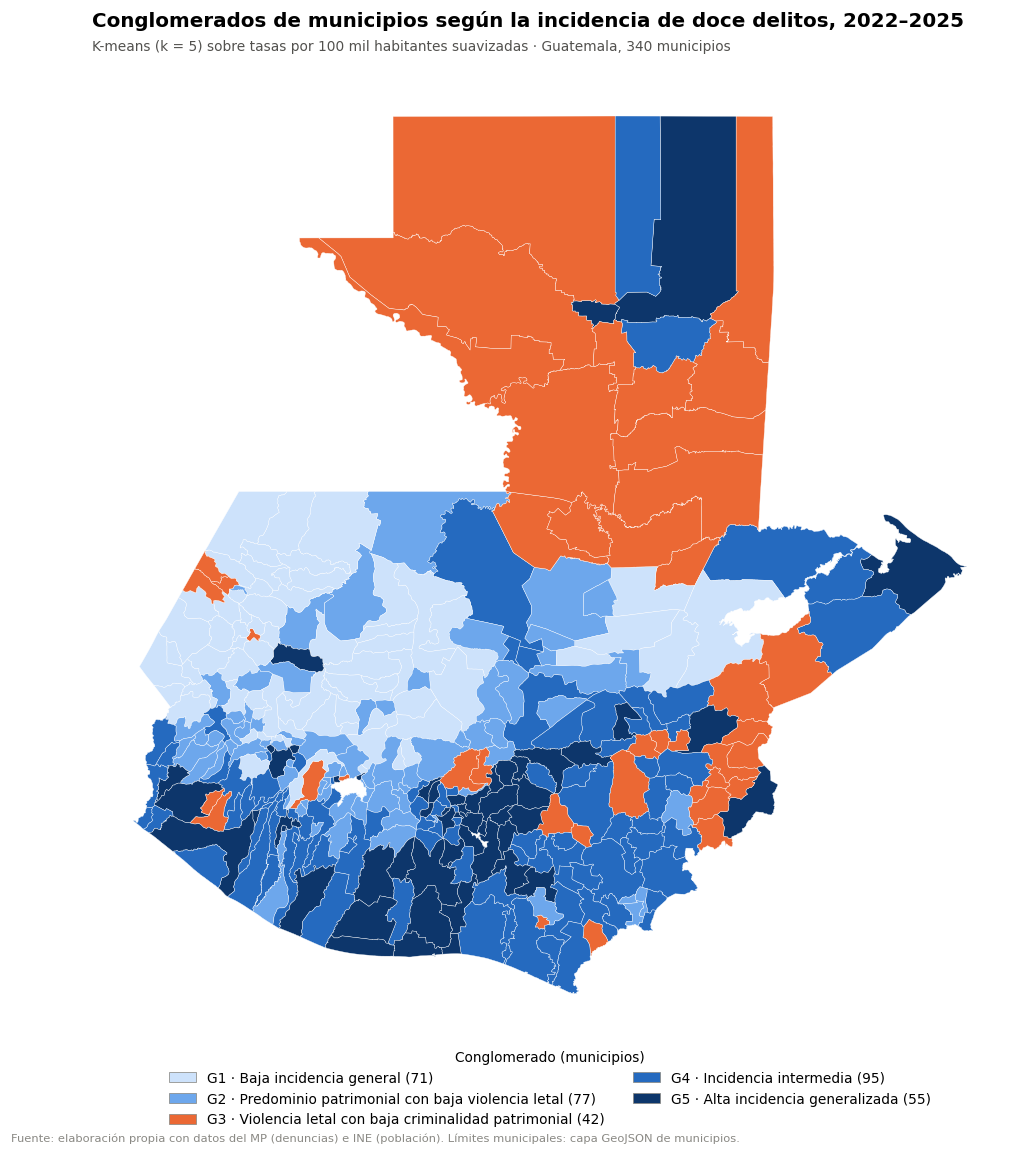

In [16]:
with open(RAIZ_PROY / "data" / "external" / "municipios_guatemala.geojson", encoding="utf-8") as f:
    geo = json.load(f)
codigos_geo = [ft["properties"]["codigo_mun"] for ft in geo["features"]]
assert sorted(codigos_geo) == sorted(grupo.index), "Los códigos del mapa no coinciden con los resultados"
area_km2 = pd.Series({ft["properties"]["codigo_mun"]: ft["properties"]["shape_area"] / 1e6 for ft in geo["features"]})

def trazos(geometria):
    """Convierte un (Multi)Polígono GeoJSON en un Path de matplotlib, respetando huecos (lagos)."""
    poligonos = geometria["coordinates"] if geometria["type"] == "MultiPolygon" else [geometria["coordinates"]]
    vertices, codigos = [], []
    for poligono in poligonos:
        for anillo in poligono:
            anillo = np.asarray(anillo)[:, :2]
            vertices.extend(anillo)
            codigos.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(anillo) - 2) + [MplPath.CLOSEPOLY])
    return MplPath(np.asarray(vertices), codigos)

def dibujar_mapa(ax, colores_por_codigo, borde=0.25):
    for ft in geo["features"]:
        cod = ft["properties"]["codigo_mun"]
        ax.add_patch(PathPatch(trazos(ft["geometry"]), facecolor=colores_por_codigo[cod],
                               edgecolor="#ffffff", linewidth=borde))
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.radians(15.5)))
    ax.axis("off")

fig, ax = plt.subplots(figsize=(10, 10.5))
dibujar_mapa(ax, {c: COLOR_CLUSTER[g] for c, g in grupo.items()})
ax.legend([Patch(facecolor=COLOR_CLUSTER[g], edgecolor=COLOR["gris"], linewidth=0.5) for g in GRUPOS],
          [f"G{g} · {NOMBRE_CLUSTER[g]} ({peso.loc[g, 'municipios']})" for g in GRUPOS],
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, title="Conglomerado (municipios)", title_fontsize=9,
          frameon=True, facecolor="white", edgecolor=COLOR["gris_claro"])
ax.set_title("Conglomerados de municipios según la incidencia de doce delitos, 2022–2025", fontsize=13, pad=30)
subtitulo(ax, "K-means (k = 5) sobre tasas por 100 mil habitantes suavizadas · Guatemala, 340 municipios")
fuente(fig, FUENTE + " Límites municipales: capa GeoJSON de municipios.")
fig.tight_layout()
guardar_figura(fig, "07_mapa_conglomerados", CARPETA_FIG)
plt.show()

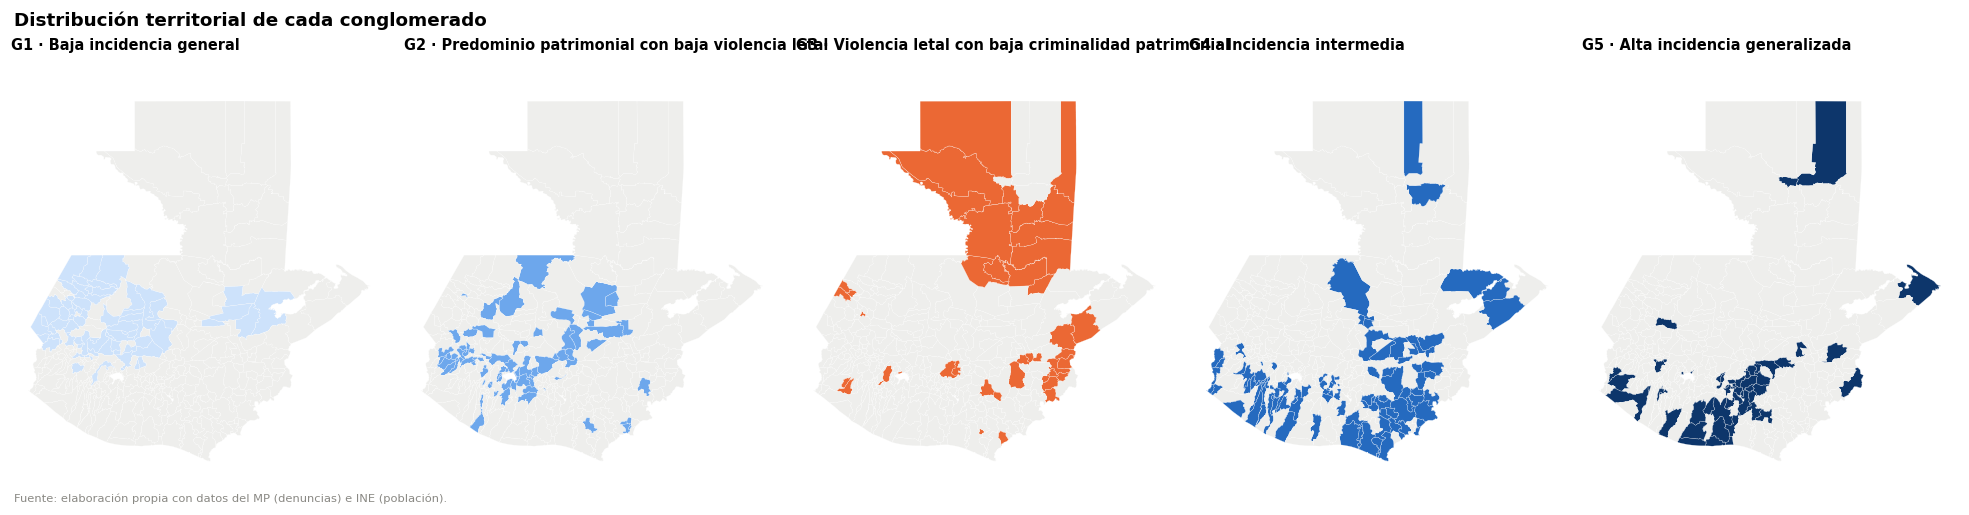

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.6))
for ax, g in zip(axes, GRUPOS):
    dibujar_mapa(ax, {c: (COLOR_CLUSTER[g] if gg == g else "#eeeeec") for c, gg in grupo.items()}, borde=0.15)
    ax.set_title(f"G{g} · {NOMBRE_CLUSTER[g]}", fontsize=9.5)
fig.suptitle("Distribución territorial de cada conglomerado", x=0.01, ha="left", fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.94))
guardar_figura(fig, "08_mapas_por_conglomerado", CARPETA_FIG)
plt.show()

### 9.3 Autocorrelación espacial: ¿los grupos forman regiones?

El modelo **no recibió ninguna información geográfica**: ni coordenadas, ni departamento, ni vecindad. Si aun así los municipios vecinos tienden a quedar en el mismo grupo, es evidencia de que los perfiles responden a **dinámicas territoriales reales** y no a ruido. Es una validación **externa** a la partición, sin la circularidad de la sección 5.

Se construye la **vecindad** a partir de la capa geográfica: dos municipios son vecinos si comparten un tramo de frontera (criterio *rook*), detectado por vértices compartidos. Luego se aplican dos pruebas con **9,999 permutaciones** (se reordenan al azar los grupos o valores entre municipios, conservando los tamaños):

- **Join counts** (Cliff y Ord, 1981): ¿hay más pares de vecinos del **mismo grupo** de lo que produciría el azar?
- **I de Moran** (Moran, 1950): ¿las tasas de municipios vecinos se parecen más de lo esperado? Varía de −1 a 1; 0 = sin patrón espacial.

In [18]:
from collections import defaultdict

vertices = defaultdict(set)
for ft in geo["features"]:
    cod = ft["properties"]["codigo_mun"]
    poligonos = ft["geometry"]["coordinates"] if ft["geometry"]["type"] == "MultiPolygon" else [ft["geometry"]["coordinates"]]
    for poligono in poligonos:
        for anillo in poligono:
            for x, y in anillo:
                vertices[(round(x, 5), round(y, 5))].add(cod)
compartidos = defaultdict(int)
for municipios in vertices.values():
    m = sorted(municipios)
    for i in range(len(m)):
        for j in range(i + 1, len(m)):
            compartidos[(m[i], m[j])] += 1
aristas = np.array([par for par, n in compartidos.items() if n >= 2])   # ≥ 2 vértices = frontera compartida
pos = {c: i for i, c in enumerate(grupo.index)}
ai = np.array([pos[a] for a in aristas[:, 0]])
bi = np.array([pos[b] for b in aristas[:, 1]])
vecinos = np.bincount(np.concatenate([ai, bi]), minlength=len(grupo))
print(f"Pares de municipios vecinos: {len(aristas)} · vecinos por municipio: media {vecinos.mean():.1f}, "
      f"mínimo {vecinos.min()}, máximo {vecinos.max()} · municipios sin vecinos: {(vecinos == 0).sum()}")

rng_esp = np.random.default_rng(42)
N_PERM = 9999
lab = grupo.values

def prueba_permutacion(observado, estadistico, datos):
    simulados = np.array([estadistico(rng_esp.permutation(datos)) for _ in range(N_PERM)])
    p = (np.sum(simulados >= observado) + 1) / (N_PERM + 1)
    z = (observado - simulados.mean()) / simulados.std()
    return simulados.mean(), z, p

# Join counts: pares de vecinos en el mismo grupo
mismo = lambda l: np.sum(l[ai] == l[bi])
obs_jc = mismo(lab)
esp_jc, z_jc, p_jc = prueba_permutacion(obs_jc, mismo, lab)

# I de Moran (pesos binarios de vecindad)
def moran(v):
    z = v - v.mean()
    return len(v) / (2 * len(aristas)) * (2 * np.sum(z[ai] * z[bi])) / np.sum(z ** 2)

variables_moran = {
    "Tasa total (log)": np.log1p(base["Tasa_total"].values),
    "Índice patrimonial y extorsivo (log)": np.log(indice_dimension(DIMENSIONES["Patrimonial y extorsiva"], por=None).values + 0.01),
    "Índice de violencia letal (log)": np.log(indice_dimension(DIMENSIONES["Violencia letal"], por=None).values + 0.01),
}
filas = [{"prueba": "Join counts: pares de vecinos en el mismo grupo", "observado": obs_jc,
          "esperado al azar": esp_jc, "z": z_jc, "p (permutación)": p_jc}]
for nombre, v in variables_moran.items():
    I = moran(v)
    esp, z, p = prueba_permutacion(I, moran, v)
    filas.append({"prueba": f"I de Moran: {nombre}", "observado": I, "esperado al azar": esp, "z": z, "p (permutación)": p})
espacial = pd.DataFrame(filas).set_index("prueba")
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
display(espacial)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(f"{obs_jc / len(aristas):.0%} de los pares de vecinos pertenecen al mismo grupo "
      f"(al azar se esperaría {esp_jc / len(aristas):.0%}).")

Pares de municipios vecinos: 933 · vecinos por municipio: media 5.5, mínimo 1, máximo 12 · municipios sin vecinos: 0


,observado,esperado al azar,z,p (permutación)
prueba,,,,
Join counts: pares de vecinos en el mismo grupo,432,197.7,18.99,0.0001
I de Moran: Tasa total (log),0.6194,-0.00287,19.15,0.0001
I de Moran: Índice patrimonial y extorsivo (log),0.63,-0.003078,19.45,0.0001
I de Moran: Índice de violencia letal (log),0.5221,-0.002655,16.3,0.0001


46% de los pares de vecinos pertenecen al mismo grupo (al azar se esperaría 21%).


,observado,esperado al azar,razón obs/esp
grupo,,,
G1,63.77,20.65,3.09
G2,36.71,22.42,1.64
G3,43.40,12.09,3.59
G4,44.57,27.73,1.61
G5,40.65,15.93,2.55


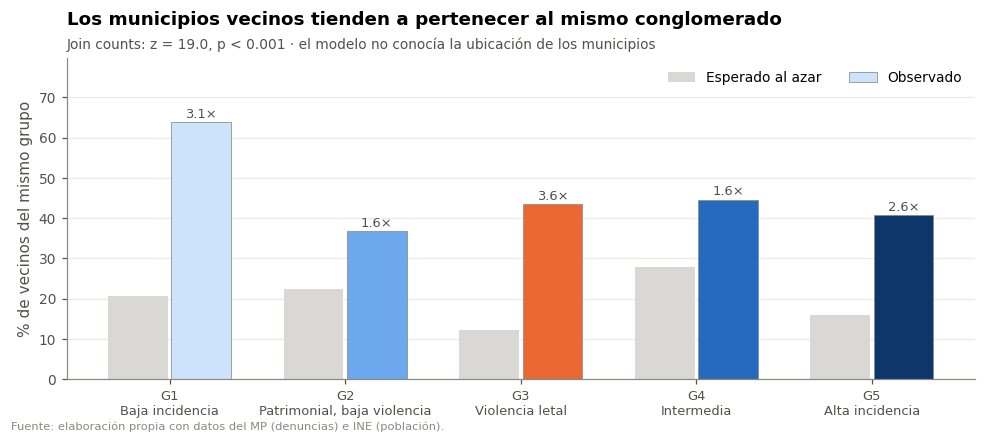

In [19]:
# Homofilia por grupo: % de los vecinos de un municipio del grupo g que también son del grupo g
homofilia = []
for g in GRUPOS:
    idx = np.flatnonzero(lab == g)
    vec_mismo = sum(np.sum((ai == i) & (lab[bi] == g)) + np.sum((bi == i) & (lab[ai] == g)) for i in idx)
    vec_total = vecinos[idx].sum()
    homofilia.append({"grupo": f"G{g}", "observado": vec_mismo / vec_total * 100,
                      "esperado al azar": ((lab == g).sum() - 1) / (len(lab) - 1) * 100})
homofilia = pd.DataFrame(homofilia).set_index("grupo")
homofilia["razón obs/esp"] = homofilia["observado"] / homofilia["esperado al azar"]
display(homofilia)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(5)
ax.bar(x - 0.18, homofilia["esperado al azar"], width=0.34, color=COLOR["gris_claro"], label="Esperado al azar")
ax.bar(x + 0.18, homofilia["observado"], width=0.34, color=[COLOR_CLUSTER[g] for g in GRUPOS],
       edgecolor=COLOR["gris"], linewidth=0.5, label="Observado")
for i, (o, r) in enumerate(zip(homofilia["observado"], homofilia["razón obs/esp"])):
    ax.text(i + 0.18, o + 1.2, f"{r:.1f}×", ha="center", fontsize=8.5, color=COLOR["texto_sec"])
ax.set_xticks(x, [f"G{g}\n{NOMBRE_CORTO_CLUSTER[g]}" for g in GRUPOS], fontsize=8.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% de vecinos del mismo grupo")
ax.set_ylim(0, homofilia["observado"].max() * 1.25)
ax.set_title("Los municipios vecinos tienden a pertenecer al mismo conglomerado")
subtitulo(ax, f"Join counts: z = {z_jc:.1f}, p < 0.001 · el modelo no conocía la ubicación de los municipios")
ax.legend(loc="upper right", ncol=2)
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "10_autocorrelacion_espacial", CARPETA_FIG)
plt.show()

**Lectura:** los municipios vecinos comparten grupo mucho más de lo que produciría el azar, y las tasas muestran una autocorrelación espacial positiva y significativa. Como el modelo nunca recibió información geográfica, esta coherencia territorial es una **validación externa**: los conglomerados capturan patrones regionales reales.

> Nota: parte de esta autocorrelación puede deberse a factores compartidos por municipios vecinos (desarrollo, rutas, presencia institucional) o al registro de denuncias en fiscalías que atienden a varios municipios (ver limitaciones). No implica que la criminalidad "se contagie".

## 10. Exportación para Tableau

Se generan cuatro archivos en `outputs/tableau/`, todos con el **código de municipio del INE** como llave de unión:

| Archivo | Granularidad | Uso en Tableau |
|---|---|---|
| `tableau_municipios.csv` | 1 fila por municipio (340) | Mapa, fichas municipales, filtros, rankings |
| `tableau_municipios_anual.csv` | municipio × año × delito (16,320) | Tendencias, selector de delito, composición |
| `tableau_perfil_conglomerados.csv` | conglomerado × delito (60) | Mapa de calor del perfil, comparaciones |
| `municipios_guatemala_conglomerados.geojson` | 340 polígonos | Capa espacial con el conglomerado ya incluido |

> **Regla clave para Tableau:** las tasas de un grupo **no se promedian**. Se calculan como `SUM([Denuncias]) / SUM([Población persona-años]) * 100000`. Por eso los archivos incluyen conteos y poblaciones, no solo tasas.

In [20]:
nivel_k3 = {1: "Baja", 2: "Media", 3: "Alta"}
ranking = base["Tasa_total"].rank(ascending=False, method="min").astype(int)
tasa_total_anual = (anual.groupby(["Codigo_Municipio", "Anio"])["Denuncias"].sum()
                    / poblacion.set_index(["Codigo_Municipio", "Anio"])["Poblacion"] * 1e5).unstack()
pob_w = poblacion.pivot_table(index="Codigo_Municipio", columns="Anio", values="Poblacion")

t = pd.DataFrame(index=base.index)
t["Codigo Municipio"] = base.index
t["Codigo Departamento"] = base.index // 100
t["Departamento"] = base["Departamento"]
t["Municipio"] = base["Municipio"]
t["Municipio (nombre MP)"] = base["Municipio_MP"]
t["Conglomerado"] = grupo
t["Conglomerado Etiqueta"] = grupo.map(lambda g: f"G{g} · {NOMBRE_CLUSTER[g]}")
t["Conglomerado Nombre"] = grupo.map(NOMBRE_CLUSTER)
t["Conglomerado Nombre Corto"] = grupo.map(NOMBRE_CORTO_CLUSTER)
t["Conglomerado Descripcion"] = grupo.map(DESCRIPCION_CLUSTER)
t["Conglomerado Color"] = grupo.map(COLOR_CLUSTER)
t["Nivel Agregado (k=3)"] = resultado["grupo_k3"].map(nivel_k3)
t["Silueta"] = resultado["silueta"].round(4)
t["Distancia al Centroide"] = resultado["distancia_centroide"].round(4)
t["Municipio Representativo"] = t.index.isin(representativos.index)
t["Municipio de Frontera"] = resultado["silueta"] < 0
t["Poblacion Promedio 2022-2025"] = base["Poblacion_prom"].round(0).astype(int)
for a in ANIOS_ESTUDIO:
    t[f"Poblacion {a}"] = pob_w[a].astype(int)
t["Poblacion Persona-Anios 2022-2025"] = exposicion.astype(int)
t["Area km2"] = area_km2.reindex(base.index).round(2)
t["Densidad hab/km2"] = (t["Poblacion Promedio 2022-2025"] / t["Area km2"]).round(1)
t["Denuncias Total 2022-2025"] = base["Denuncias_total"]
t["Tasa Total x100k"] = base["Tasa_total"].round(2)
t["Indice Tasa Total vs Nacional"] = (base["Tasa_total"] / (conteos.values.sum() / exposicion.sum() * 1e5)).round(3)
t["Ranking Nacional Tasa Total"] = ranking
for a in ANIOS_ESTUDIO:
    t[f"Tasa Total x100k {a}"] = tasa_total_anual[a].round(2)
t["Variacion Tasa Total 2022-2025 %"] = ((tasa_total_anual[2025] / tasa_total_anual[2022].replace(0, np.nan) - 1) * 100).round(1)
for f in familias:
    cols = [c for c in CODIGOS_DELITO if FAMILIA_COD[c] == f]
    t[f"Denuncias Familia {f}"] = conteos[cols].sum(axis=1)
    t[f"% Mezcla {f}"] = (conteos[cols].sum(axis=1) / base["Denuncias_total"] * 100).round(1)
for d, cols in DIMENSIONES.items():
    if d != "Total":
        t[f"Indice {d} vs Nacional"] = indice_dimension(cols, por=None).round(3)
for c in CODIGOS_DELITO:
    nombre = CODIGO_A_CORTO[c]
    t[f"Denuncias {nombre}"] = conteos[c]
    t[f"Tasa {nombre} x100k"] = tasas[c].round(2)
    t[f"Tasa Suavizada {nombre} x100k"] = suav[f"tasa_eb_{c}"].round(2)
    t[f"Indice {nombre} vs Nacional"] = (tasas[c] / tasa_nac[c]).round(3)
t = t.reset_index(drop=True)
t.to_csv(RUTA_TABLEAU / "tableau_municipios.csv", index=False, encoding="utf-8-sig")
print(f"tableau_municipios.csv: {t.shape[0]} filas × {t.shape[1]} columnas")

tableau_municipios.csv: 340 filas × 92 columnas


In [21]:
largo = anual.merge(poblacion[["Codigo_Municipio", "Anio", "Poblacion"]], on=["Codigo_Municipio", "Anio"])
largo = pd.DataFrame({
    "Codigo Municipio": largo["Codigo_Municipio"],
    "Anio": largo["Anio"],
    "Delito": largo["Codigo_Delito"].map(CODIGO_A_CORTO),
    "Delito (nombre completo)": largo["Delito"],
    "Familia de Delito": largo["Codigo_Delito"].map(FAMILIA_COD),
    "Denuncias": largo["Denuncias"],
    "Poblacion": largo["Poblacion"],
    "Tasa x100k": (largo["Denuncias"] / largo["Poblacion"] * 1e5).round(3),
})
largo = largo.merge(t[["Codigo Municipio", "Departamento", "Municipio", "Conglomerado",
                       "Conglomerado Etiqueta", "Conglomerado Nombre"]], on="Codigo Municipio")
assert len(largo) == 340 * 4 * 12 and largo["Denuncias"].sum() == conteos.values.sum()
largo.to_csv(RUTA_TABLEAU / "tableau_municipios_anual.csv", index=False, encoding="utf-8-sig")
print(f"tableau_municipios_anual.csv: {largo.shape[0]:,} filas × {largo.shape[1]} columnas")

tableau_municipios_anual.csv: 16,320 filas × 13 columnas


In [22]:
centroides = pd.read_csv(RUTA_REPORTES / "07_centroides_finales.csv", index_col=0)
filas = []
for g in GRUPOS:
    for c in CODIGOS_DELITO:
        filas.append({"Conglomerado": g, "Conglomerado Etiqueta": f"G{g} · {NOMBRE_CLUSTER[g]}",
                      "Delito": CODIGO_A_CORTO[c], "Familia de Delito": FAMILIA_COD[c],
                      "Denuncias": int(conteos.loc[grupo == g, c].sum()),
                      "Poblacion Persona-Anios": int(exposicion[grupo == g].sum()),
                      "Tasa Agregada x100k": round(tasa_grupo.loc[c, g], 3),
                      "Tasa Nacional x100k": round(tasa_nac[c], 3),
                      "Indice vs Nacional": round(indice.loc[c, g], 3),
                      "Mediana Tasa Municipal x100k": round(mediana.loc[c, g], 3),
                      "Kruskal-Wallis epsilon2": round(kw.loc[CODIGO_A_CORTO[c], "épsilon²"], 3)})
perfil = pd.DataFrame(filas)
perfil.to_csv(RUTA_TABLEAU / "tableau_perfil_conglomerados.csv", index=False, encoding="utf-8-sig")
print(f"tableau_perfil_conglomerados.csv: {perfil.shape[0]} filas × {perfil.shape[1]} columnas")

tableau_perfil_conglomerados.csv: 60 filas × 11 columnas


In [23]:
props = t.set_index("Codigo Municipio")[["Departamento", "Municipio", "Conglomerado", "Conglomerado Etiqueta",
                                         "Conglomerado Nombre", "Tasa Total x100k", "Poblacion Promedio 2022-2025"]]
geo_out = {"type": "FeatureCollection", "features": []}
for ft in geo["features"]:
    cod = ft["properties"]["codigo_mun"]
    p = props.loc[cod]
    geo_out["features"].append({"type": "Feature", "geometry": ft["geometry"], "properties": {
        "Codigo Municipio": int(cod), "Departamento": p["Departamento"], "Municipio": p["Municipio"],
        "Conglomerado": int(p["Conglomerado"]), "Conglomerado Etiqueta": p["Conglomerado Etiqueta"],
        "Conglomerado Nombre": p["Conglomerado Nombre"], "Tasa Total x100k": float(p["Tasa Total x100k"]),
        "Poblacion Promedio 2022-2025": int(p["Poblacion Promedio 2022-2025"])}})
with open(RUTA_TABLEAU / "municipios_guatemala_conglomerados.geojson", "w", encoding="utf-8") as f:
    json.dump(geo_out, f, ensure_ascii=False)
print(f"municipios_guatemala_conglomerados.geojson: {len(geo_out['features'])} polígonos")

with open(RUTA_REPORTES / "08_nombres_conglomerados.json", "w", encoding="utf-8") as f:
    json.dump({str(g): {"nombre": NOMBRE_CLUSTER[g], "nombre_corto": NOMBRE_CORTO_CLUSTER[g],
                        "descripcion": DESCRIPCION_CLUSTER[g],
                        "indice_patrimonial_extorsiva": round(float(ejes.loc[f"G{g}", "Patrimonial y extorsiva"]), 3),
                        "indice_violencia_letal": round(float(ejes.loc[f"G{g}", "Violencia letal"]), 3),
                        "color": COLOR_CLUSTER[g]} for g in GRUPOS}, f, ensure_ascii=False, indent=2)

municipios_guatemala_conglomerados.geojson: 340 polígonos


## 11. Conclusiones

**¿Se sostiene $k = 5$?** Sí. Los cinco perfiles se confirman con **tasas reales**, **cada nombre supera sus condiciones de verificación** y los grupos forman **regiones coherentes** aunque el modelo no conocía la ubicación de los municipios (sección 9.3). Las diferencias entre grupos son grandes en los delitos patrimoniales, la extorsión y la violencia letal (ε² de 0.52 a 0.78) y pequeñas o medianas en los delitos sexuales agravados (ε² de 0.05 a 0.24). Esas magnitudes se reportan de forma **descriptiva**, sin usarlas como prueba de validez (sección 5).

| Grupo | Municipios | % población | % denuncias | Patrimonial y extorsiva | Violencia letal |
|---|---|---|---|---|---|
| **G1 · Baja incidencia general** | 71 | 20 % | 3 % | 0.11× | 0.15× |
| **G2 · Predominio patrimonial con baja violencia letal** | 77 | 17 % | 6 % | 0.34× | 0.20× |
| **G3 · Violencia letal con baja criminalidad patrimonial** | 42 | 11 % | 4 % | 0.25× | **1.05×** |
| **G4 · Incidencia intermedia** | 95 | 20 % | 15 % | 0.70× | 0.95× |
| **G5 · Alta incidencia generalizada** | 55 | 32 % | 72 % | **2.36×** | **1.96×** |

Los grupos forman una **tipología en dos ejes**: criminalidad patrimonial y extorsiva frente a violencia letal (figura `09_tipologia_dos_ejes`). La violencia sexual varía poco entre grupos (0.67× a 1.30×) y no define ningún perfil.

**Matiz importante sobre el G3:** frente al G2, su homicidio es claramente mayor (efecto grande, $r = 0.90$). Frente al G4, su homicidio es **similar** (efecto pequeño, $r = 0.17$). Lo que distingue al G3 del G4 es la **ausencia** de delitos patrimoniales y extorsión ($r$ de −0.70 a −0.91). Por eso su nombre describe una **combinación**: violencia letal **con** baja criminalidad patrimonial. Este perfil se concentra en **Petén** (71 % de sus municipios), **Chiquimula**, **Zacapa** y **Jalapa**, en el norte y el oriente del país.

**Territorio:** el patrón geográfico es claro. El altiplano occidental (Huehuetenango, Quiché, Totonicapán) es de **baja incidencia**. El corredor central y la costa sur (Guatemala, Escuintla, Sacatepéquez) concentran la **alta incidencia**. El norte y el oriente muestran el perfil de **violencia letal con baja criminalidad patrimonial**. Esto se confirma estadísticamente: los municipios vecinos comparten grupo mucho más de lo esperado por azar (join counts y I de Moran, $p < 0.001$). Como el modelo **no conocía la ubicación** de los municipios, esta coherencia territorial es una **validación externa** del resultado.

**Evolución 2022–2025:** la **extorsión creció en todos los grupos** (de +53 % a +129 %), mientras que robos y hurtos bajaron (de −16 % a −30 %). En el G3, homicidio y asesinato **aumentaron un 28 %**, en contraste con los demás grupos, donde se mantuvieron estables. Su perfil violento se intensificó.

**Municipios de frontera:** solo 8 de 340 (2.4 %) tienen silueta negativa. Ningún grupo depende de casos ambiguos.
